# Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there 'right away' or 'later before the coupon expires' are labeled as 'Y = 1' and answers 'no, I do not want the coupon' are labeled as 'Y = 0'. There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - \$50).

### Data Description

1. User attributes: gender, age, marital status, number of children, education, occupation, annual income, and how often the respondent visits bars, coffee houses, takeaway, cheap restaurants (< \$20) and mid-priced restaurants (\$20-\$50).
2. Contextual attributes: driving destination, direction and driving time to the venue, weather, temperature, time of day, passenger.
3. Coupon attributes: time before it expires (2 hours or one day).

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path

IMG = Path('images'); IMG.mkdir(exist_ok=True)

# Fixed categorical palette (identity never changes between charts)
ACCEPT, REJECT, NEUTRAL = '#2a78d6', '#eb6834', '#9a9891'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
sns.set_theme(style='white', context='notebook')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e6e5e1',
                     'axes.edgecolor': '#c3c2b7', 'figure.dpi': 110})

def rate_bar(series, title, ax=None, order=None, color=ACCEPT, baseline=None, fname=None, xlabel=''):
    """Horizontal bar of acceptance rate (mean of Y) per category, with n in the label."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 0.5 * len(series) + 1.5))
    s = series if order is None else series.reindex(order)
    ax.barh(s.index.astype(str), s['mean'], color=color, height=0.6)
    for i, (m, n) in enumerate(zip(s['mean'], s['count'])):
        ax.text(m + 0.01, i, f'{m:.0%}  (n={int(n):,})', va='center', fontsize=9, color='#52514e')
    if baseline is not None:
        ax.axvline(baseline, color=NEUTRAL, ls='--', lw=1)
        ax.text(baseline, -0.55, f' overall {baseline:.0%}', color='#52514e', fontsize=8)
    ax.set_xlim(0, 1); ax.set_xlabel(xlabel or 'Acceptance rate'); ax.set_title(title, loc='left', fontweight='bold')
    ax.invert_yaxis(); ax.grid(axis='x'); ax.grid(False, axis='y')
    if fname:
        plt.tight_layout(); plt.savefig(IMG / fname, bbox_inches='tight')
    return ax

def rate_by(df, col, order=None):
    g = df.groupby(col, observed=True)['Y'].agg(['mean', 'count'])
    return g if order is None else g.reindex([o for o in order if o in g.index])

### 1. Read in the `coupons.csv` file.

In [2]:
data = pd.read_csv('data/coupons.csv')
print(data.shape)
data.head()

(12684, 26)


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


### 2. Investigate the dataset for missing or problematic data.

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  str  
 12  occupation            12684 non-null  str  
 13  income                12684 non-null  str  
 14  car                   108 non-null    str  
 15  Bar                   12577 non-null  str  
 16  CoffeeHouse    

In [4]:
missing = pd.DataFrame({'missing': data.isnull().sum(), 'pct': (data.isnull().mean() * 100).round(2)})
missing[missing.missing > 0]

,missing,pct
car,12576,99.15
Bar,107,0.84
CoffeeHouse,217,1.71
CarryAway,151,1.19
RestaurantLessThan20,130,1.02
Restaurant20To50,189,1.49


In [5]:
print('Duplicate rows:', data.duplicated().sum())
print('Target balance:'); print(data['Y'].value_counts())
print()
print('temperature values:', sorted(data['temperature'].unique()))
print('time values:', sorted(data['time'].unique()))
print('passanger values:', sorted(data['passanger'].unique()))
print('age values:', sorted(data['age'].unique()))
print('Bar values:', data['Bar'].unique())
print('car values:', data['car'].dropna().unique())

Duplicate rows: 74
Target balance:
Y
1    7210
0    5474
Name: count, dtype: int64

temperature values: [np.int64(30), np.int64(55), np.int64(80)]
time values: ['10AM', '10PM', '2PM', '6PM', '7AM']
passanger values: ['Alone', 'Friend(s)', 'Kid(s)', 'Partner']
age values: ['21', '26', '31', '36', '41', '46', '50plus', 'below21']
Bar values: <StringArray>
['never', 'less1', '1~3', 'gt8', nan, '4~8']
Length: 6, dtype: str
car values: <StringArray>
[                  'Scooter and motorcycle',
                                'crossover',
                                   'Mazda5',
                             'do not drive',
 'Car that is too old to install Onstar :D']
Length: 5, dtype: str


**Findings**

- `car` is 99% missing (108 of 12,684 rows) and carries no usable signal, so it is dropped.
- The five frequency columns (`Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50`) are each missing in 1-2% of rows. They are kept as `NaN` rather than imputed; each question that uses one of them simply excludes the rows where it is missing.
- 74 rows are exact duplicates. Because every row is a scenario shown to a survey respondent, an identical row is almost certainly a repeated submission, so duplicates are removed.
- The column `passanger` is misspelled in the source. It is renamed to `passenger`.
- `time` is a string with no natural sort order, and `age`, `income` and the frequency columns are ordinal strings. They are converted to ordered categoricals so that plots read in a meaningful order.
- The target is reasonably balanced (57% accepted), so acceptance rate per group is a fair comparison metric.

### 3. Decide what to do about your missing data -- drop, replace, other...

In [6]:
df = data.drop_duplicates().drop(columns=['car']).rename(columns={'passanger': 'passenger'}).copy()

freq_order = ['never', 'less1', '1~3', '4~8', 'gt8']
for col in ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']:
    df[col] = pd.Categorical(df[col], categories=freq_order, ordered=True)

df['time'] = pd.Categorical(df['time'], categories=['7AM', '10AM', '2PM', '6PM', '10PM'], ordered=True)
df['age'] = pd.Categorical(df['age'], categories=['below21', '21', '26', '31', '36', '41', '46', '50plus'], ordered=True)
income_order = ['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999', '$50000 - $62499',
                '$62500 - $74999', '$75000 - $87499', '$87500 - $99999', '$100000 or More']
df['income'] = pd.Categorical(df['income'], categories=income_order, ordered=True)
df['expiration'] = pd.Categorical(df['expiration'], categories=['2h', '1d'], ordered=True)

# One readable distance bucket from the three cumulative flags
df['distance'] = np.select([df['toCoupon_GEQ25min'] == 1, df['toCoupon_GEQ15min'] == 1], ['25+ min', '15-25 min'], '5-15 min')
df['distance'] = pd.Categorical(df['distance'], categories=['5-15 min', '15-25 min', '25+ min'], ordered=True)

print(df.shape)
df.isnull().sum()[df.isnull().sum() > 0]

(12610, 26)


Bar                     107
CoffeeHouse             217
CarryAway               150
RestaurantLessThan20    129
Restaurant20To50        189
dtype: int64

### 4. What proportion of the total observations chose to accept the coupon?

In [7]:
overall_rate = df['Y'].mean()
print(f'Accepted: {df.Y.sum():,} of {len(df):,} offers  ->  {overall_rate:.1%}')

Accepted: 7,157 of 12,610 offers  ->  56.8%


### 5. Use a bar plot to visualize the `coupon` column.

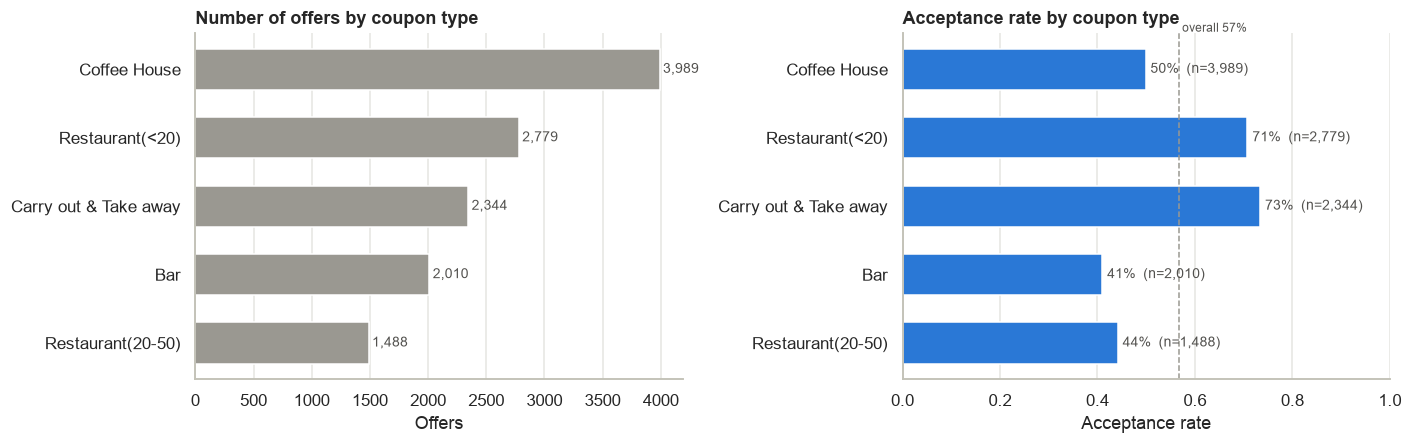

In [8]:
coupon_order = df['coupon'].value_counts().index
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
counts = df['coupon'].value_counts()
axes[0].barh(counts.index, counts.values, color=NEUTRAL, height=0.6)
for i, v in enumerate(counts.values):
    axes[0].text(v + 30, i, f'{v:,}', va='center', fontsize=9, color='#52514e')
axes[0].invert_yaxis(); axes[0].set_title('Number of offers by coupon type', loc='left', fontweight='bold')
axes[0].set_xlabel('Offers'); axes[0].grid(axis='x'); axes[0].grid(False, axis='y')

rate_bar(rate_by(df, 'coupon').reindex(coupon_order), 'Acceptance rate by coupon type', ax=axes[1], baseline=overall_rate)
plt.tight_layout(); plt.savefig(IMG / '01_coupon_types.png', bbox_inches='tight'); plt.show()

Coffee House is the most frequently offered coupon (just under a third of all offers) but is accepted only about half the time. The two food coupons that need little commitment, carry-out and cheap restaurants, are accepted over 70% of the time, while bar and mid-priced restaurant coupons are accepted well under half the time.

### 6. Use a histogram to visualize the temperature column.

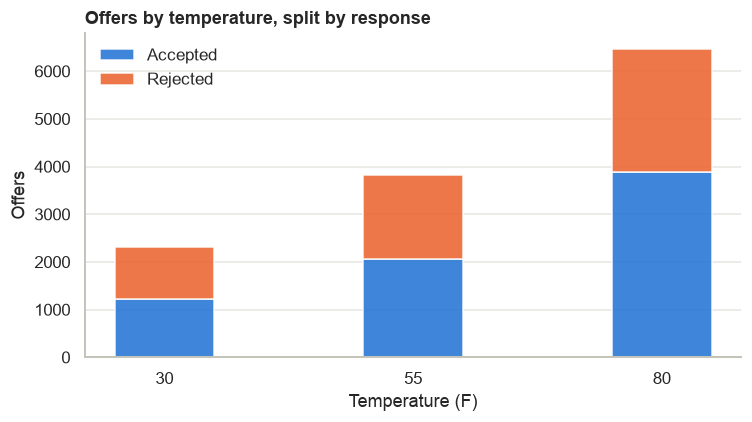

,mean,count
temperature,,
30,0.531,2305
55,0.537,3830
80,0.599,6475


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = [25, 35, 50, 60, 75, 85]
ax.hist(df.loc[df.Y == 1, 'temperature'], bins=bins, color=ACCEPT, label='Accepted', alpha=0.9)
ax.hist(df.loc[df.Y == 0, 'temperature'], bins=bins, color=REJECT, label='Rejected', alpha=0.9,
        bottom=np.histogram(df.loc[df.Y == 1, 'temperature'], bins=bins)[0])
ax.set_xticks([30, 55, 80]); ax.set_xlabel('Temperature (F)'); ax.set_ylabel('Offers')
ax.set_title('Offers by temperature, split by response', loc='left', fontweight='bold'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(IMG / '02_temperature.png', bbox_inches='tight'); plt.show()
rate_by(df, 'temperature').round(3)

Temperature takes only three values (30F, 55F, 80F), so the histogram is really three bars. Warm 80F days account for half of the offers and have the highest acceptance (60%), while 30F and 55F sit around 53-54%.

## Investigating the Bar Coupons

Now, we will lead you through an exploration of just the bar related coupons.

### 1. Create a new `DataFrame` that contains just the bar coupons.

In [10]:
bar = df[df['coupon'] == 'Bar'].copy()
print(bar.shape)
bar.head()

(2010, 26)


,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y,distance
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,NaN,4~8,1~3,1,1,0,0,1,0,15-25 min
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,NaN,4~8,1~3,1,0,0,1,0,1,5-15 min
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,NaN,4~8,1~3,1,1,1,0,1,0,25+ min
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,4~8,4~8,less1,1,0,0,0,1,1,5-15 min
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,4~8,4~8,less1,1,0,0,1,0,1,5-15 min


### 2. What proportion of bar coupons were accepted?

In [11]:
bar_rate = bar['Y'].mean()
print(f'Bar coupons accepted: {bar.Y.sum():,} of {len(bar):,}  ->  {bar_rate:.1%}  (overall rate {overall_rate:.1%})')

Bar coupons accepted: 824 of 2,010  ->  41.0%  (overall rate 56.8%)


### 3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.

group,n,accepted,rate
Goes to a bar > 3 times/month,199,153,76.9%
Goes to a bar 3 or fewer times/month,1790,663,37.0%


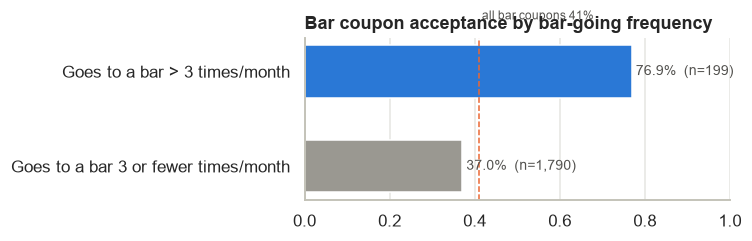

In [12]:
def compare(frame, mask, label_a, label_b, title=None, fname=None):
    """Print and plot acceptance rate for a boolean split of `frame`. Rows where mask is NA are excluded."""
    m = mask.fillna(False).astype(bool)
    valid = mask.notna()
    a, b = frame[m & valid], frame[~m & valid]
    out = pd.DataFrame({'group': [label_a, label_b], 'n': [len(a), len(b)],
                        'accepted': [a.Y.sum(), b.Y.sum()], 'rate': [a.Y.mean(), b.Y.mean()]})
    display(out.style.format({'rate': '{:.1%}'}).hide(axis='index'))
    fig, ax = plt.subplots(figsize=(7, 2.4))
    ax.barh(out.group, out.rate, color=[ACCEPT, NEUTRAL], height=0.55)
    for i, (r, n) in enumerate(zip(out.rate, out.n)):
        ax.text(r + 0.01, i, f'{r:.1%}  (n={n:,})', va='center', fontsize=9, color='#52514e')
    ax.axvline(bar_rate, color=REJECT, ls='--', lw=1); ax.text(bar_rate, -0.55, f' all bar coupons {bar_rate:.0%}', color='#52514e', fontsize=8)
    ax.set_xlim(0, 1); ax.invert_yaxis(); ax.grid(axis='x'); ax.grid(False, axis='y')
    ax.set_title(title or '', loc='left', fontweight='bold')
    if fname: plt.tight_layout(); plt.savefig(IMG / fname, bbox_inches='tight')
    plt.show()
    return out

bar_freq = bar['Bar']
goes_more_than_3 = bar_freq.isin(['4~8', 'gt8']).where(bar_freq.notna())
q3 = compare(bar, goes_more_than_3, 'Goes to a bar > 3 times/month', 'Goes to a bar 3 or fewer times/month',
             'Bar coupon acceptance by bar-going frequency', '03_bar_frequency_split.png')

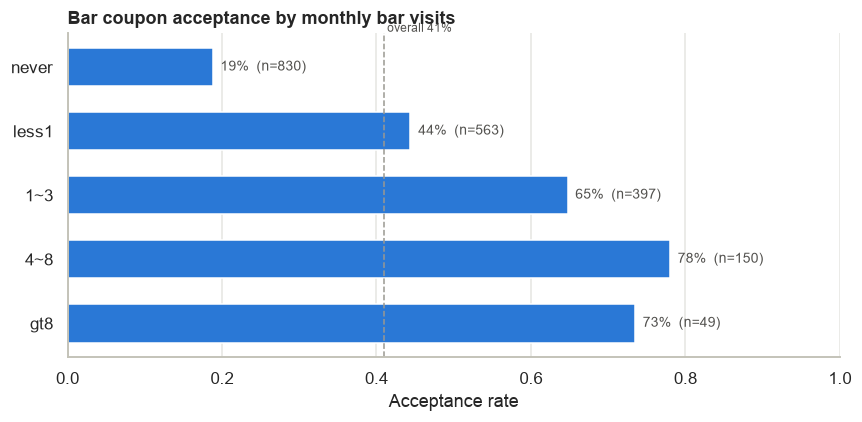

In [13]:
# The full frequency ladder makes the gradient explicit
rate_bar(rate_by(bar, 'Bar'), 'Bar coupon acceptance by monthly bar visits', baseline=bar_rate, fname='04_bar_frequency_ladder.png')
plt.show()

Drivers who go to a bar more than three times a month accept 77% of bar coupons, more than double the 37% rate of those who go three or fewer times. The ladder shows acceptance rising monotonically with bar-going habit, from 19% for people who never go to about 73-78% for frequent visitors. Note that the heavy-user group is small (199 offers).

### 4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others. Is there a difference?

group,n,accepted,rate
Bar > once/month AND age > 25,420,292,69.5%
All others,1569,524,33.4%


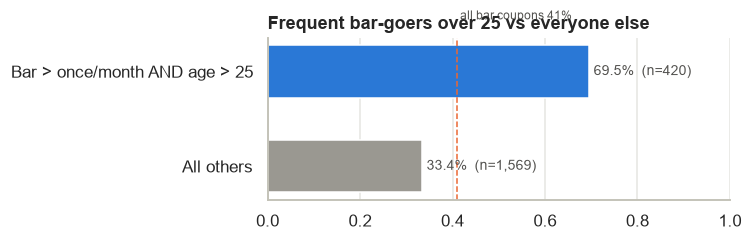

In [14]:
more_than_once = bar_freq.isin(['1~3', '4~8', 'gt8'])
over_25 = bar['age'].isin(['26', '31', '36', '41', '46', '50plus'])
q4 = compare(bar, (more_than_once & over_25).where(bar_freq.notna()),
             'Bar > once/month AND age > 25', 'All others',
             'Frequent bar-goers over 25 vs everyone else', '05_bar_over25.png')

Yes, the difference is large: 70% acceptance for drivers over 25 who go to a bar more than once a month versus 33% for all other drivers. The group is about one fifth of bar-coupon offers (420 of 1,989).

### 5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.

group,n,accepted,rate
"Bar > once/month, no kid passenger, not farming/fishing/forestry",551,393,71.3%
All others,1438,423,29.4%


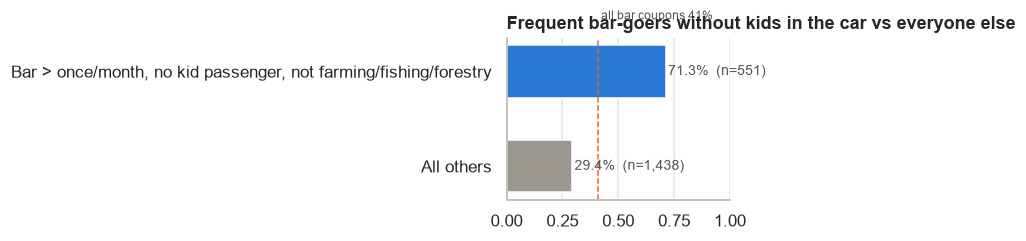

Farming/Fishing/Forestry offers in bar subset: 9


In [15]:
no_kid = bar['passenger'] != 'Kid(s)'
not_farming = bar['occupation'] != 'Farming Fishing & Forestry'
q5 = compare(bar, (more_than_once & no_kid & not_farming).where(bar_freq.notna()),
             'Bar > once/month, no kid passenger, not farming/fishing/forestry', 'All others',
             'Frequent bar-goers without kids in the car vs everyone else', '06_bar_nokid_occupation.png')
print('Farming/Fishing/Forestry offers in bar subset:', (bar.occupation == 'Farming Fishing & Forestry').sum())

71% versus 30%. The occupation filter removes almost nothing (only 9 bar offers went to farming, fishing or forestry workers), so this result is driven by bar habit and by not having a child in the car.

### 6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.

criterion,n,rate
"(1) Bar > once/month, no kid, not widowed",551,71.3%
"(2) Bar > once/month, under 30",345,72.2%
"(3) Cheap restaurants > 4/month, income < $50K",344,45.3%


group,n,accepted,rate
"Meets criterion 1, 2 or 3",776,457,58.9%
Meets none,1234,367,29.7%


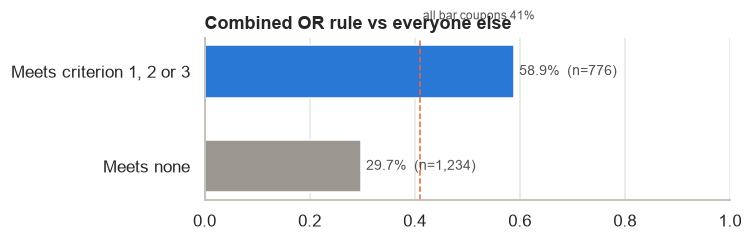

In [16]:
not_widowed = bar['maritalStatus'] != 'Widowed'
under_30 = bar['age'].isin(['below21', '21', '26'])
cheap_often = bar['RestaurantLessThan20'].isin(['4~8', 'gt8'])
income_under_50k = bar['income'].isin(['Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999'])

c1 = more_than_once & no_kid & not_widowed
c2 = more_than_once & under_30
c3 = cheap_often & income_under_50k

parts = pd.DataFrame({
    'criterion': ['(1) Bar > once/month, no kid, not widowed', '(2) Bar > once/month, under 30',
                  '(3) Cheap restaurants > 4/month, income < $50K'],
    'n': [c1.sum(), c2.sum(), c3.sum()],
    'rate': [bar[c1].Y.mean(), bar[c2].Y.mean(), bar[c3].Y.mean()]})
display(parts.style.format({'rate': '{:.1%}'}).hide(axis='index'))

q6 = compare(bar, (c1 | c2 | c3), 'Meets criterion 1, 2 or 3', 'Meets none',
             'Combined OR rule vs everyone else', '07_bar_combined_rule.png')

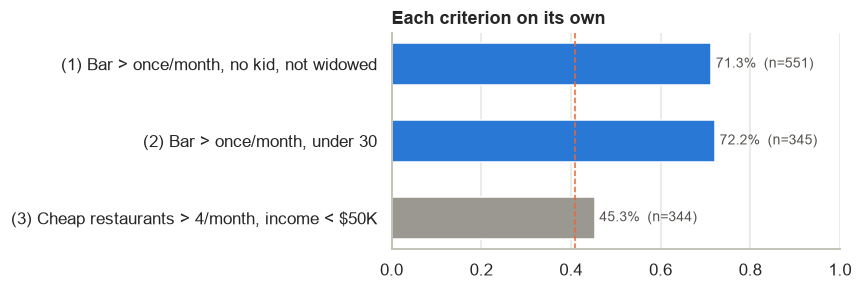

In [17]:
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(parts.criterion, parts.rate, color=[ACCEPT, ACCEPT, NEUTRAL], height=0.55)
for i, (r, n) in enumerate(zip(parts.rate, parts.n)):
    ax.text(r + 0.01, i, f'{r:.1%}  (n={n:,})', va='center', fontsize=9, color='#52514e')
ax.axvline(bar_rate, color=REJECT, ls='--', lw=1)
ax.set_xlim(0, 1); ax.invert_yaxis(); ax.grid(axis='x'); ax.grid(False, axis='y')
ax.set_title('Each criterion on its own', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig(IMG / '08_bar_criteria_separately.png', bbox_inches='tight'); plt.show()

Drivers meeting any of the three criteria accept 59% of bar coupons versus 30% for those meeting none. But the three criteria are not equal. The two bar-habit criteria each reach 71-72% acceptance, while the third (frequent cheap-restaurant diners with income under \$50K) sits at 45%, barely above the bar average of 41%. Adding criterion 3 dilutes the rule: it brings in people who like eating out cheaply but who have no particular bar habit.

### 7. Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

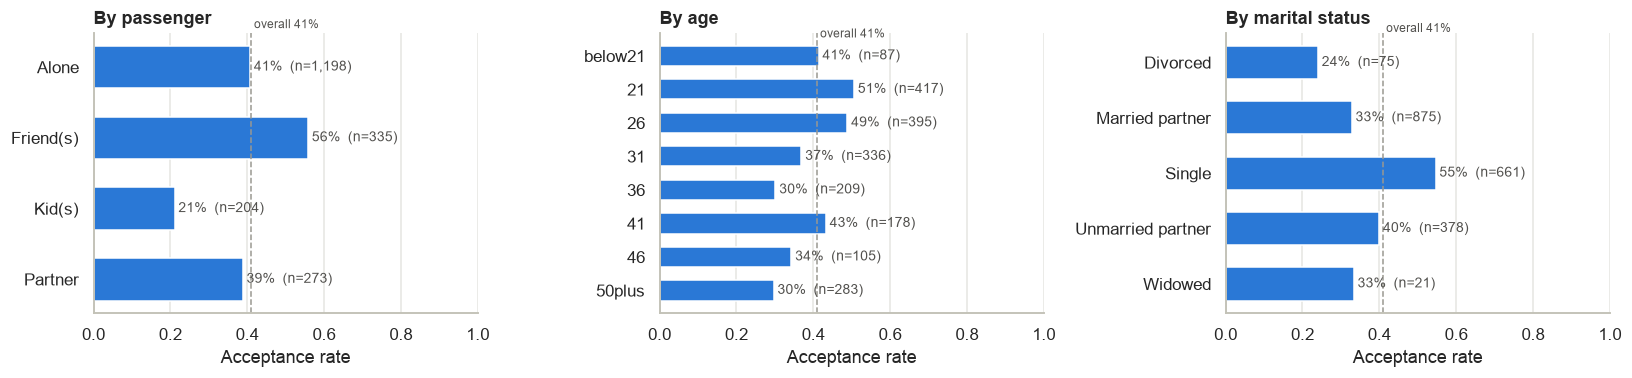

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
rate_bar(rate_by(bar, 'passenger'), 'By passenger', ax=axes[0], baseline=bar_rate)
rate_bar(rate_by(bar, 'age'), 'By age', ax=axes[1], baseline=bar_rate)
rate_bar(rate_by(bar, 'maritalStatus'), 'By marital status', ax=axes[2], baseline=bar_rate)
plt.tight_layout(); plt.savefig(IMG / '09_bar_passenger_age_marital.png', bbox_inches='tight'); plt.show()

**Hypothesis.** Bar coupons are accepted by people who already go to bars. Existing habit is by far the strongest signal: acceptance climbs from 19% for people who never go to a bar to roughly 75% for those who go more than three times a month, and every successful filter above is essentially a proxy for "goes to a bar at least monthly". Two secondary factors modulate that habit:

- **Who is in the car.** Having a child as the passenger cuts acceptance to 21%; riding with friends raises it to 56%. A bar is a social, adults-only destination, and the passenger makes it feasible or not.
- **Life stage.** Drivers under 30 accept at about 50%, those over 35 at roughly 30-35%. Younger drivers are both more likely to be bar-goers and to be single.

Variables that look like lifestyle proxies but do not touch bar-going (cheap-restaurant frequency, income under \$50K, occupation) add little. A coupon engine should target bar coupons at self-reported bar-goers, suppress them when a child is in the car, and expect weak returns on everyone else.

## Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.

### Coffee House coupons

Coffee House is the largest coupon group (3,989 offers) and the one closest to a coin flip (50% acceptance), so it has the most room for targeting to improve outcomes.

In [19]:
coffee = df[df['coupon'] == 'Coffee House'].copy()
coffee_rate = coffee['Y'].mean()
print(f'Coffee House coupons accepted: {coffee.Y.sum():,} of {len(coffee):,}  ->  {coffee_rate:.1%}')

Coffee House coupons accepted: 1,989 of 3,989  ->  49.9%


#### Does habit matter as much as it did for bars?

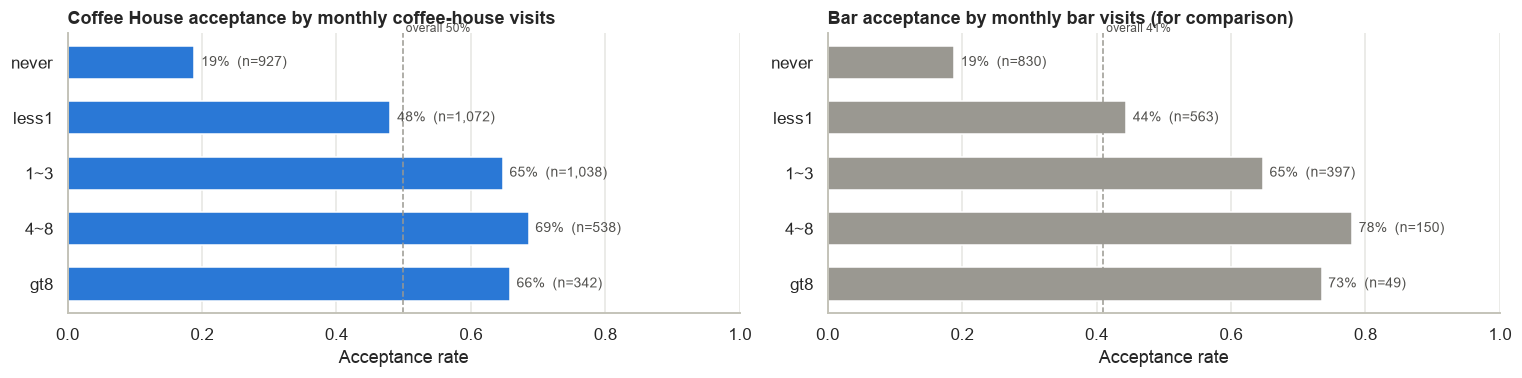

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
rate_bar(rate_by(coffee, 'CoffeeHouse'), 'Coffee House acceptance by monthly coffee-house visits', ax=axes[0], baseline=coffee_rate)
rate_bar(rate_by(bar, 'Bar'), 'Bar acceptance by monthly bar visits (for comparison)', ax=axes[1], baseline=bar_rate, color=NEUTRAL)
plt.tight_layout(); plt.savefig(IMG / '10_coffee_vs_bar_habit.png', bbox_inches='tight'); plt.show()

Habit matters, but it saturates early. People who never visit coffee houses accept only 19%, the same floor as bar non-goers. The jump happens at "less than once a month" (48%) and again at "1 to 3 times" (65%); beyond that, going more often barely moves the needle (66-69%). Compared with bars, a coffee coupon converts occasional visitors almost as well as regulars, so the addressable audience is far wider: 75% of coffee-coupon recipients visit at least occasionally.

#### Context: when, where to, and with whom

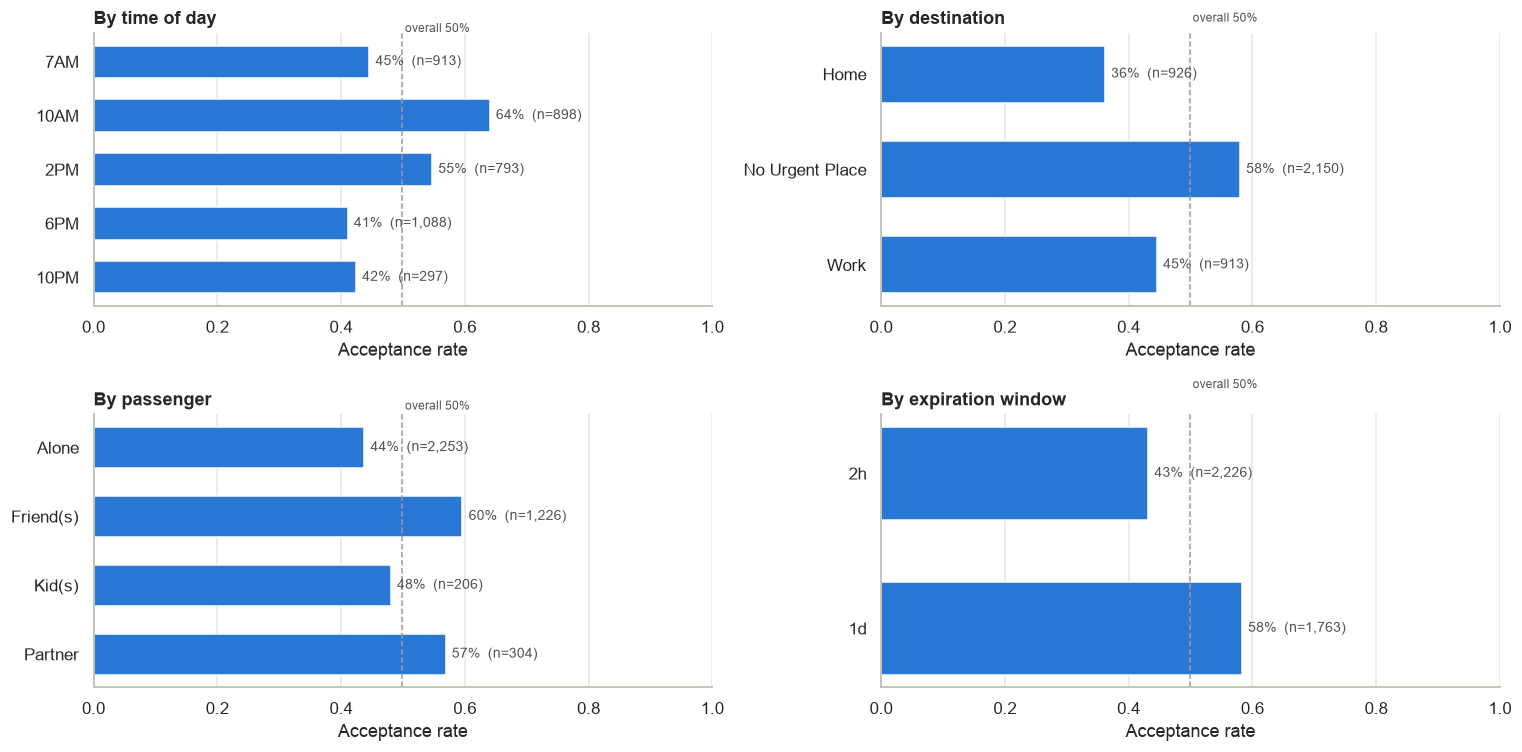

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
rate_bar(rate_by(coffee, 'time'), 'By time of day', ax=axes[0, 0], baseline=coffee_rate)
rate_bar(rate_by(coffee, 'destination'), 'By destination', ax=axes[0, 1], baseline=coffee_rate)
rate_bar(rate_by(coffee, 'passenger'), 'By passenger', ax=axes[1, 0], baseline=coffee_rate)
rate_bar(rate_by(coffee, 'expiration'), 'By expiration window', ax=axes[1, 1], baseline=coffee_rate)
plt.tight_layout(); plt.savefig(IMG / '11_coffee_context.png', bbox_inches='tight'); plt.show()

In [22]:
# Time and destination are entangled in the survey design: morning/afternoon scenarios are 'No Urgent Place', 7AM is 'Work', 6PM/10PM are mostly 'Home'
pd.crosstab(coffee['time'], coffee['destination'], values=coffee['Y'], aggfunc='mean').round(2).fillna('-')

/var/folders/rk/cc4fj3355s56vgkj2tj6x9t00000gn/T/ipykernel_3805/158206735.py:2: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.crosstab(coffee['time'], coffee['destination'], values=coffee['Y'], aggfunc='mean').round(2).fillna('-')


destination,Home,No Urgent Place,Work
time,,,
7AM,-,-,0.45
10AM,-,0.64,-
2PM,-,0.55,-
6PM,0.38,0.47,-
10PM,0.28,0.68,-


- **Time of day.** 10AM is the best moment (64%), 2PM is next (55%). Early morning on the way to work (7AM, 45%) and evening (6PM, 41%) are poor.
- **Destination.** Drivers with no urgent destination accept 58%; those heading home accept only 36%. The survey design ties time and destination together (10AM and 2PM scenarios are always "No Urgent Place"), so these two findings are largely the same finding: a coffee detour works when the driver has slack in their schedule.
- **Passenger.** Friends (60%) and partner (57%) beat driving alone (44%). Unlike bars, a child in the car does not hurt coffee acceptance (48%).
- **Expiration.** A one-day coupon is accepted 58% of the time versus 43% for a two-hour coupon. Coffee is a "later today" purchase, and a short fuse kills it.

#### Distance and weather

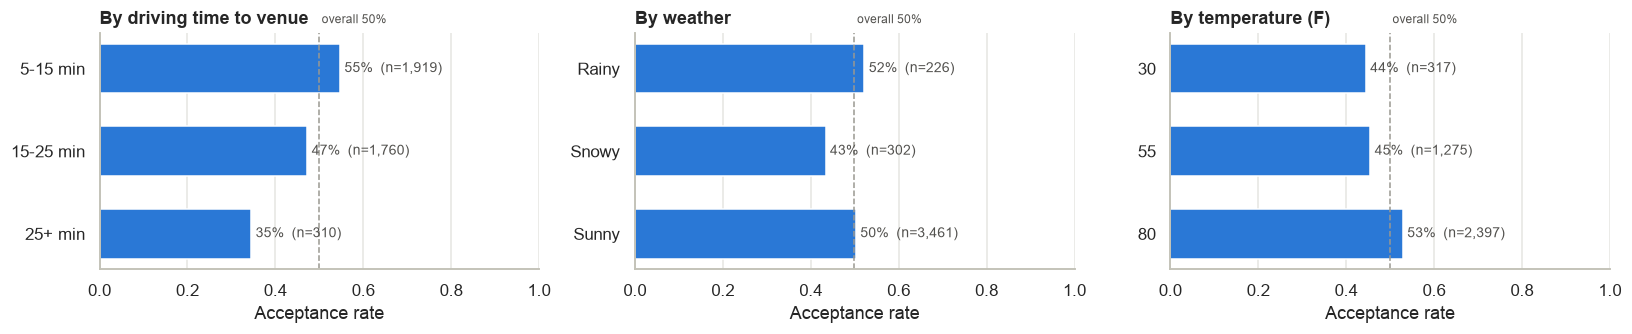

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
rate_bar(rate_by(coffee, 'distance'), 'By driving time to venue', ax=axes[0], baseline=coffee_rate)
rate_bar(rate_by(coffee, 'weather'), 'By weather', ax=axes[1], baseline=coffee_rate)
rate_bar(rate_by(coffee, 'temperature'), 'By temperature (F)', ax=axes[2], baseline=coffee_rate)
plt.tight_layout(); plt.savefig(IMG / '12_coffee_distance_weather.png', bbox_inches='tight'); plt.show()

Distance matters in the expected direction: 55% when the venue is within 15 minutes, 45% at 15-25 minutes, 35% beyond 25 minutes. Weather and temperature have small effects (warm sunny days are slightly better; snow slightly worse) and are second-order compared with timing and habit.

#### Demographics

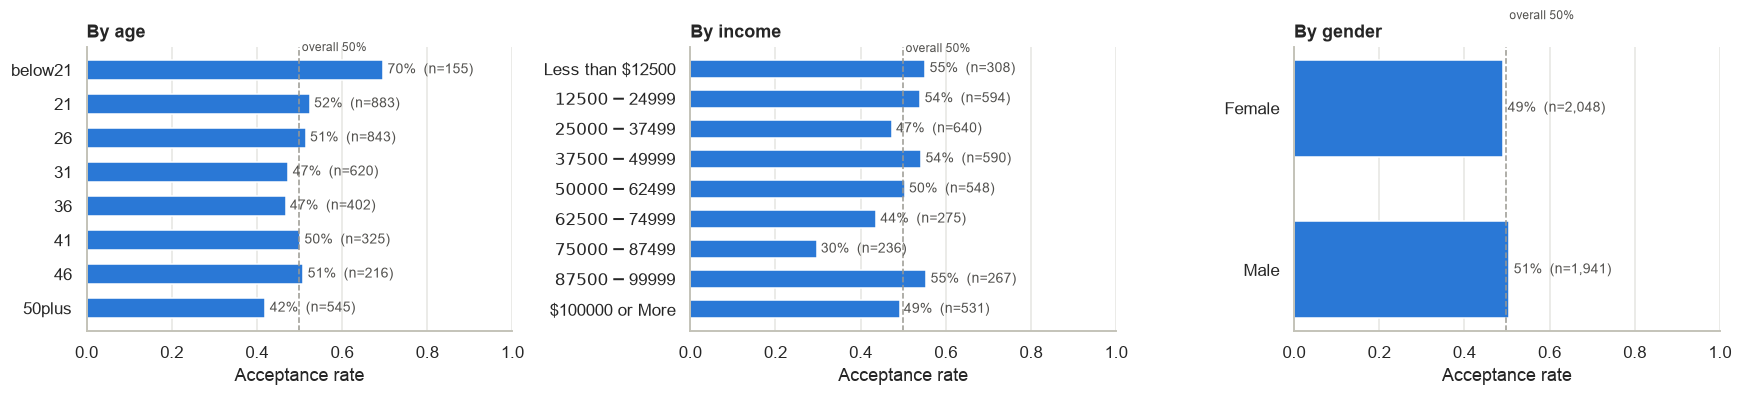

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
rate_bar(rate_by(coffee, 'age'), 'By age', ax=axes[0], baseline=coffee_rate)
rate_bar(rate_by(coffee, 'income'), 'By income', ax=axes[1], baseline=coffee_rate)
rate_bar(rate_by(coffee, 'gender'), 'By gender', ax=axes[2], baseline=coffee_rate)
plt.tight_layout(); plt.savefig(IMG / '13_coffee_demographics.png', bbox_inches='tight'); plt.show()

Demographics are weak predictors for coffee. Gender makes no difference (49% vs 51%). Age is flat around 47-52% except for the under-21 group (70%, but only 155 offers) and the over-50 group (42%). Income shows no consistent trend; the \$75K-\$87.5K dip to 30% is an isolated cell and likely noise from a small group.

#### Putting it together: habit x expiration, and a targeting rule

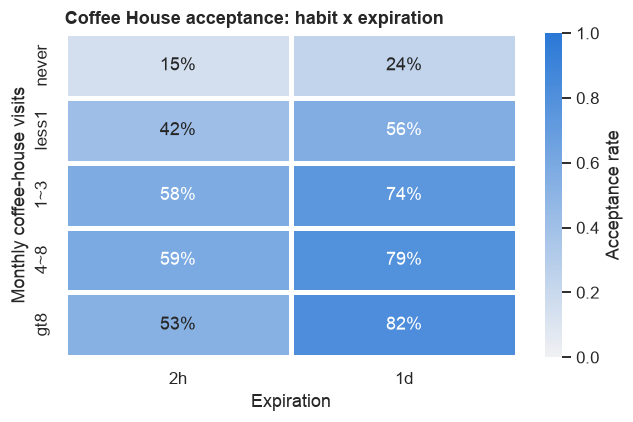

expiration,2h,1d
CoffeeHouse,,
never,502,425
less1,599,473
1~3,609,429
4~8,281,257
gt8,191,151


In [25]:
heat = pd.crosstab(coffee['CoffeeHouse'], coffee['expiration'], values=coffee['Y'], aggfunc='mean')
counts = pd.crosstab(coffee['CoffeeHouse'], coffee['expiration'])
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(heat, annot=heat.map(lambda v: f'{v:.0%}'), fmt='', cmap=sns.light_palette(ACCEPT, as_cmap=True),
            vmin=0, vmax=1, cbar_kws={'label': 'Acceptance rate'}, linewidths=2, linecolor='white', ax=ax)
ax.set_title('Coffee House acceptance: habit x expiration', loc='left', fontweight='bold')
ax.set_xlabel('Expiration'); ax.set_ylabel('Monthly coffee-house visits')
plt.tight_layout(); plt.savefig(IMG / '14_coffee_habit_expiration.png', bbox_inches='tight'); plt.show()
counts

,n,rate
All coffee coupons,3989,49.9%
Visits coffee house >= 1/month,1918,66.0%
... AND no urgent destination,1036,73.8%
... AND one-day expiration,480,80.2%
Never visits AND heading home,223,9.4%


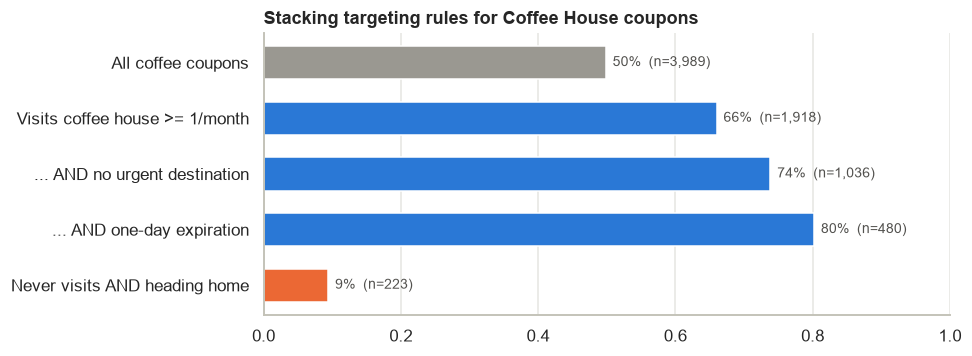

In [26]:
visits_monthly = coffee['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])
slack = coffee['destination'] == 'No Urgent Place'
near = coffee['distance'] != '25+ min'
one_day = coffee['expiration'] == '1d'

rules = {
    'All coffee coupons': pd.Series(True, index=coffee.index),
    'Visits coffee house >= 1/month': visits_monthly,
    '... AND no urgent destination': visits_monthly & slack,
    '... AND one-day expiration': visits_monthly & slack & one_day,
    'Never visits AND heading home': (coffee['CoffeeHouse'] == 'never') & (coffee['destination'] == 'Home'),
}
summary = pd.DataFrame({name: {'n': int(m.sum()), 'rate': coffee.loc[m.fillna(False).astype(bool), 'Y'].mean()}
                        for name, m in rules.items()}).T
summary['n'] = summary['n'].astype(int)
display(summary.style.format({'rate': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(9, 3.4))
colors = [NEUTRAL] + [ACCEPT] * 3 + [REJECT]
ax.barh(summary.index, summary.rate, color=colors, height=0.6)
for i, (r, n) in enumerate(zip(summary.rate, summary.n)):
    ax.text(r + 0.01, i, f'{r:.0%}  (n={n:,})', va='center', fontsize=9, color='#52514e')
ax.set_xlim(0, 1); ax.invert_yaxis(); ax.grid(axis='x'); ax.grid(False, axis='y')
ax.set_title('Stacking targeting rules for Coffee House coupons', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig(IMG / '15_coffee_targeting_rules.png', bbox_inches='tight'); plt.show()

**What characterises drivers who accept Coffee House coupons**

1. **They already drink coffee out, even occasionally.** Monthly visitors accept about two thirds of coupons; people who never go accept one in five. Unlike bars, there is no extra lift from being a heavy user.
2. **They have time.** Mid-morning and early afternoon, with no urgent destination, is when coffee coupons work. The evening commute home is the worst moment (36-41%).
3. **They are given room to redeem.** A one-day window lifts acceptance by about 15 points over a two-hour window across every habit level. Regulars with a one-day coupon accept 74-82%.
4. **They are not driving alone.** Friends or a partner in the car add 13-16 points; a child does not hurt.
5. **Demographics barely matter.** Age, gender, income and marital status are flat compared with the context variables above.

Stacking the first three rules identifies a segment (480 offers, about 12% of coffee coupons) that accepts 80% of the time, versus a disengaged segment (never visits, heading home) that accepts only 9%. The practical recommendation is to send coffee coupons at 10AM-2PM to drivers with any coffee habit, with a one-day expiry, and to withhold them on the evening commute.

## Summary of findings

| Finding | Evidence |
|---|---|
| 57% of all offers were accepted | 7,157 of 12,610 de-duplicated offers |
| Low-commitment food coupons convert best | Carry-out 73%, cheap restaurants 71%, coffee 50%, mid-priced restaurants 44%, bar 41% |
| Bar coupons go to bar-goers | 19% acceptance for never-goers, about 75% for those visiting more than 3 times a month |
| A child in the car kills bar coupons | 21% with kids vs 56% with friends |
| Coffee coupons need slack, not loyalty | Occasional visitors convert almost as well as regulars; 10AM with no urgent destination is the best moment |
| Expiration window matters for coffee | 1-day 58% vs 2-hour 43%, consistent across habit levels |

**Next steps.** Fit a logistic regression or tree model per coupon type to quantify these effects jointly and check for interactions (for example habit x passenger), and validate the targeting rules on a held-out split before using them to decide which coupons to send.